# Module 4 — Delay Risk Classification & Explainability

## Business question
Given an order at creation time, what is its probability of being delayed — and, critically,
*why* — so it can become operational action (prioritize, switch carrier, alert customer)?

## Data leakage audit (critical)
Any variable that only exists *after* delivery must not enter the model, since at prediction
time it would not yet exist. The following columns are excluded for this reason:
`Days for shipping (real)`, `Delivery Status`, `shipping date (DateOrders)`. `Late_delivery_risk`
is the target, not a feature. All remaining features (shipping mode, region, category, customer
segment, market, order date parts, order value) are known at order-creation time.

## 1. Setup & imports

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb
import shap

from classification import evaluate_classifier, expected_savings

pd.set_option('display.max_columns', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 2. Load data and engineer order-time-only features

In [2]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin1')
df.columns = [c.strip() for c in df.columns]
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_dow'] = df['order date (DateOrders)'].dt.dayofweek
df = df.sort_values('order date (DateOrders)').reset_index(drop=True)

LEAKAGE_COLUMNS = ['Days for shipping (real)', 'Delivery Status', 'shipping date (DateOrders)']
FEATURES = ['Shipping Mode', 'Order Region', 'Category Name', 'Customer Segment',
            'Market', 'order_month', 'order_dow', 'Order Item Total']
TARGET = 'Late_delivery_risk'

assert not set(FEATURES) & set(LEAKAGE_COLUMNS), "Leakage column found in feature set!"

data = df[FEATURES + [TARGET]].dropna().copy()
print(f"Modeling sample: {data.shape[0]:,} rows, {len(FEATURES)} raw features (leakage-audited)")
print(f"Target balance: {data[TARGET].mean():.1%} late")


Modeling sample: 180,519 rows, 8 raw features (leakage-audited)
Target balance: 54.8% late


## 3. Encode features & chronological train/test split
A chronological split (not random) respects the order in which orders actually arrive, avoiding future information leaking into training.

In [3]:
cat_cols = ['Shipping Mode', 'Order Region', 'Category Name', 'Customer Segment', 'Market']
X = pd.get_dummies(data[FEATURES], columns=cat_cols, drop_first=True)
y = data[TARGET].values

split_idx = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"Train: {X_train.shape[0]:,} orders | Test: {X_test.shape[0]:,} orders (chronological, no shuffling)")


Train: 144,415 orders | Test: 36,104 orders (chronological, no shuffling)


## 4. Baseline: logistic regression

In [4]:
logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train, y_train)
logreg_scores = logreg.predict_proba(X_test)[:, 1]

logreg_metrics = evaluate_classifier(y_test, logreg_scores)
pd.Series(logreg_metrics)


auc_roc                   0.727168
auc_pr                    0.793201
brier_score               0.197647
precision_at_top_10pct    0.945983
dtype: float64

## 5. Main model: XGBoost

In [5]:
xgb_model = xgb.XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss',
)
xgb_model.fit(X_train, y_train)
xgb_scores = xgb_model.predict_proba(X_test)[:, 1]

xgb_metrics = evaluate_classifier(y_test, xgb_scores)
pd.Series(xgb_metrics)


auc_roc                   0.725314
auc_pr                    0.790996
brier_score               0.198478
precision_at_top_10pct    0.944044
dtype: float64

XGBoost does not outperform the logistic
regression baseline by a meaningful margin on this feature set — both land around AUC-ROC ≈ 0.73, AUC-PR ≈ 0.79, and
~94–95% precision among the top 10% highest-risk orders. The result is honest, not
disappointing: it indicates the signal in these order-time features is largely linear and
dominated by a single categorical variable (confirmed by SHAP in Section 7), so the added
model complexity of XGBoost is not buying much here — a useful finding for deciding what to
actually deploy.

## 6. Probability calibration

In [6]:
calibrated_model = CalibratedClassifierCV(
    xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss'),
    method='isotonic', cv=3,
)
calibrated_model.fit(X_train, y_train)
calibrated_scores = calibrated_model.predict_proba(X_test)[:, 1]

calibrated_metrics = evaluate_classifier(y_test, calibrated_scores)
comparison = pd.DataFrame({'uncalibrated_xgb': xgb_metrics, 'calibrated_xgb': calibrated_metrics})
comparison


,uncalibrated_xgb,calibrated_xgb
auc_roc,0.725314,0.725985
auc_pr,0.790996,0.783191
brier_score,0.198478,0.197820
precision_at_top_10pct,0.944044,0.948199


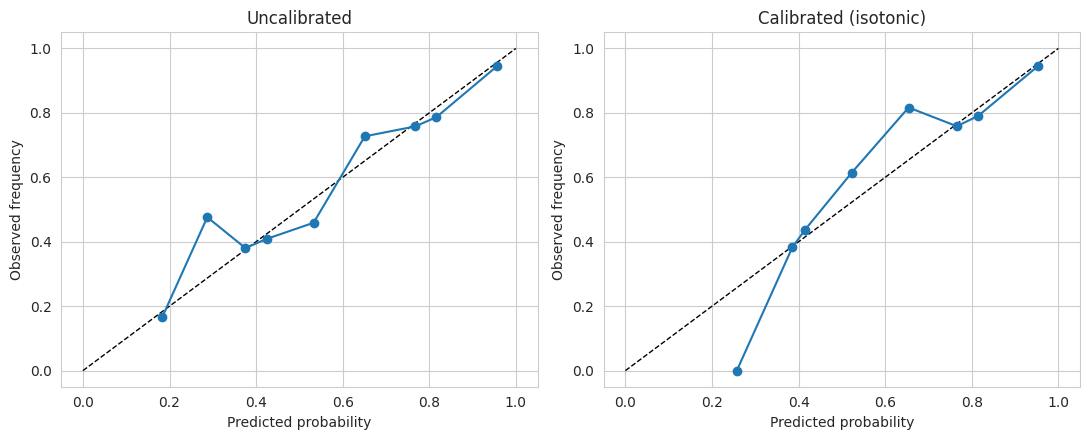

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, scores, title in zip(axes, [xgb_scores, calibrated_scores], ['Uncalibrated', 'Calibrated (isotonic)']):
    bins = np.linspace(0, 1, 11)
    bin_ids = np.digitize(scores, bins) - 1
    bin_ids = np.clip(bin_ids, 0, 9)
    observed = [y_test[bin_ids == b].mean() if (bin_ids == b).sum() > 0 else np.nan for b in range(10)]
    predicted = [scores[bin_ids == b].mean() if (bin_ids == b).sum() > 0 else np.nan for b in range(10)]
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.plot(predicted, observed, marker='o')
    ax.set_title(title)
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Observed frequency')
plt.tight_layout()
plt.savefig('../reports/figures/module4_calibration.png', dpi=120)
plt.show()


## 7. SHAP explainability

In [8]:
explainer = shap.TreeExplainer(xgb_model)
sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(sample)

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns).sort_values(ascending=False)
mean_abs_shap.head(10)


Shipping Mode_Standard Class    1.119157
Shipping Mode_Second Class      0.316057
Shipping Mode_Same Day          0.206938
Order Item Total                0.031533
order_dow                       0.023609
Order Region_Western Europe     0.019725
order_month                     0.015903
Customer Segment_Corporate      0.009239
Market_Europe                   0.008978
Order Region_Caribbean          0.007289
dtype: float32

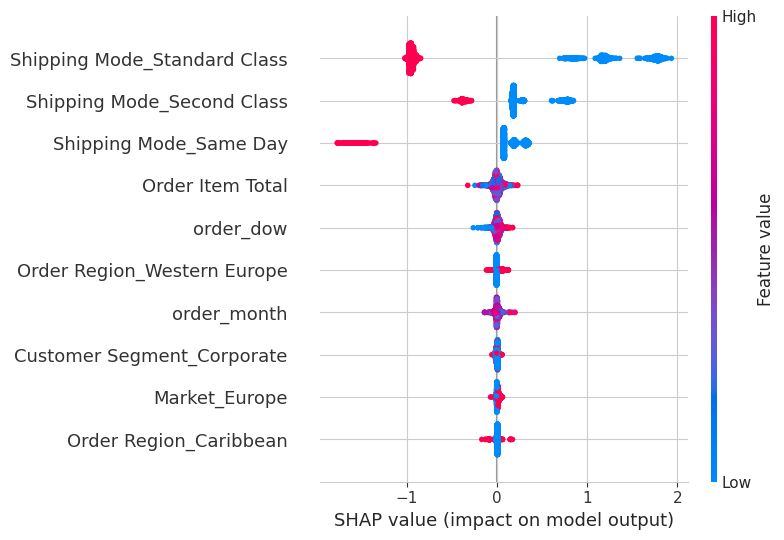

In [9]:
fig = plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, sample, show=False, max_display=10)
plt.tight_layout()
plt.savefig('../reports/figures/module4_shap_summary.png', dpi=120, bbox_inches='tight')
plt.show()


**Global reading:** `Shipping Mode` dominates the model's decisions by a wide margin —
consistent with Module 1's causal finding and Module 2's hazard analysis, all three modules
converge on shipping mode as the central lever. Order value, day of week, and region contribute
comparatively little.

## 8. Local explanation: a single high-risk order

Predicted delay probability: 97.33%


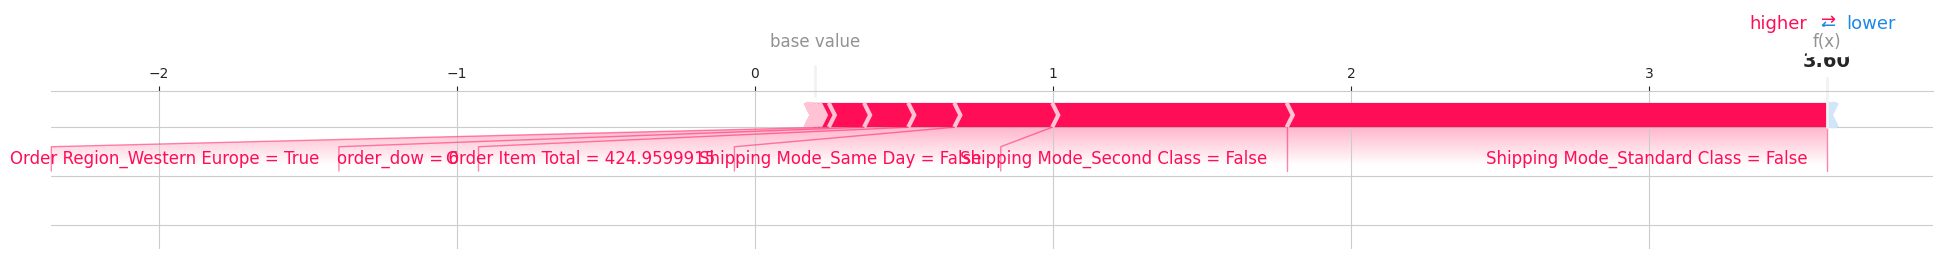

In [10]:
highest_risk_idx = np.argmax(xgb_model.predict_proba(sample)[:, 1])
order_row = sample.iloc[[highest_risk_idx]]
print(f"Predicted delay probability: {xgb_model.predict_proba(order_row)[:, 1][0]:.2%}")

shap.force_plot(
    explainer.expected_value, shap_values[highest_risk_idx], order_row,
    matplotlib=True, show=False,
)
plt.tight_layout()
plt.savefig('../reports/figures/module4_shap_local_example.png', dpi=120, bbox_inches='tight')
plt.show()


## 9. Financial translation: acting on the top-K risk orders

In [11]:
profit_by_outcome = df.groupby('Late_delivery_risk')['Order Profit Per Order'].mean()
penalty_per_delay = profit_by_outcome[0] - profit_by_outcome[1]
print(f"Average profit gap between on-time and late orders: ${penalty_per_delay:.2f} per order (descriptive, not causal)")

k = int(len(y_test) * 0.10)
savings_estimate = expected_savings(y_test, xgb_scores, k, penalty_per_delay)
print(f"If operations could act on the top {k:,} highest-risk orders (10% of the test set) "
      f"and fully prevent the delay, the estimated upper-bound benefit is "
      f"${savings_estimate:,.2f} over this holdout period.")


Average profit gap between on-time and late orders: $0.78 per order (descriptive, not causal)
If operations could act on the top 3,610 highest-risk orders (10% of the test set) and fully prevent the delay, the estimated upper-bound benefit is $2,665.40 over this holdout period.


## 10. Conclusions & limitations

**Findings:**
- The model achieves AUC-ROC ≈ 0.73 and, more operationally relevant, ~94–95% precision when
  acting on the top 10% highest-risk orders — a workable trigger for manual review or proactive
  customer communication.
- XGBoost does not beat logistic regression by a meaningful margin here; the dominant signal
  (`Shipping Mode`) is largely linear, so simplicity is not costing predictive power — worth remembering when choosing what to
  put into production.
- SHAP confirms shipping mode as the dominant driver, consistent with the causal (Module 1) and
  survival (Module 2) findings — three independent methods point to the same lever.

**Limitations:**
- The financial translation in Section 9 uses a descriptive profit gap between late and on-time
  orders, not a causally estimated dollar effect of intervention — it is an upper-bound
  illustration, not a guaranteed return.
- Precision@10% is high partly because the target is fairly balanced (54.8% late) and
  correlates strongly with an already-visible feature (shipping mode) — in a deployment
  setting the value of the model is less about discovering *that* Second Class is risky
  (already visible) and more about ranking risk *within* a shipping mode, which merits a
  dedicated follow-up analysis stratified by mode.